
Dataset Shape: (1797, 64)
Number of Features: 64

K-MEANS CLUSTERING RESULTS
 K   Inertia Silhouette Score
 2 100423.84           0.1056
 3  93842.48           0.1053
 4  89213.97           0.0954
 5  85096.05           0.1023
 6  81678.47           0.0988
 7  77749.33           0.1135
 8  74854.16           0.1266
 9  72029.73           0.1360
10  69813.56           0.1394
11  67261.85           0.1532
12  65031.72           0.1543
13  62763.18           0.1565
14  61963.42           0.1562
15  59534.50           0.1583
16  59448.73           0.1520
17  57038.16           0.1497
18  57000.79           0.1555
19  55043.49           0.1568
20  54099.96           0.1579
21  52256.06           0.1614
22  52149.01           0.1339
23  50465.62           0.1481
24  49361.89           0.1371
25  48893.02           0.1591
26  48243.84           0.1228
27  46667.28           0.1643

BEST K BASED ON SILHOUETTE SCORE
Number of Clusters: 27
Silhouette Score: 0.1643


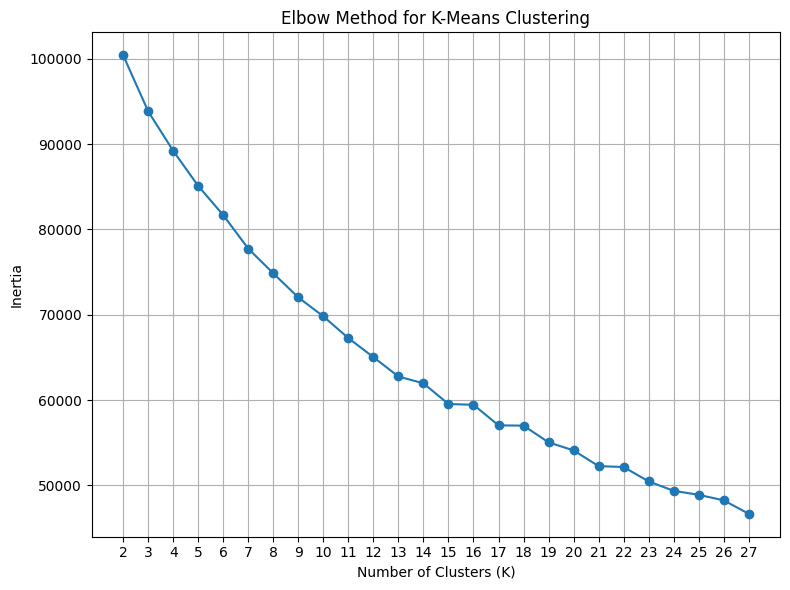

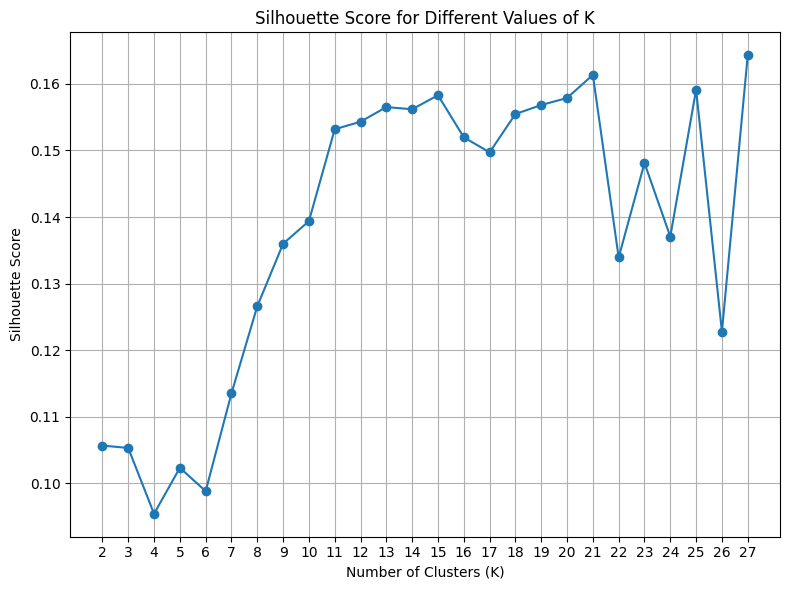

In [1]:
# ============================================================
# K-Means Clustering on Digits Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# ------------------------------------------------------------
# 1. Load the Digits Dataset
# ------------------------------------------------------------

digits = load_digits()

X = digits.data

print("\nDataset Shape:", X.shape)
print("Number of Features:", X.shape[1])


# ------------------------------------------------------------
# 2. Preprocess the data
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ------------------------------------------------------------
# 3. Define different numbers of clusters
# ------------------------------------------------------------

k_values = range(2, 28)

results = []


# ------------------------------------------------------------
# 4. Apply K-Means for different values of K
# ------------------------------------------------------------

for k in k_values:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    # Train the K-Means model
    model.fit(X_scaled)

    # Get cluster labels
    labels = model.labels_

    # Calculate inertia
    inertia = model.inertia_

    # Calculate silhouette score
    silhouette = silhouette_score( X_scaled, labels)

    # Store results
    results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("K-MEANS CLUSTERING RESULTS")
print("=" * 60)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Inertia": "{:.2f}".format,
            "Silhouette Score": "{:.4f}".format
        }
    )
)


# ------------------------------------------------------------
# 6. Find K with highest silhouette score
# ------------------------------------------------------------

best_model = results_df.loc[
    results_df["Silhouette Score"].idxmax()
]

print("\n" + "=" * 60)
print("BEST K BASED ON SILHOUETTE SCORE")
print("=" * 60)

print("Number of Clusters:", int(best_model["K"]))
print(
    "Silhouette Score:",
    round(best_model["Silhouette Score"], 4)
)


# ------------------------------------------------------------
# 7. Elbow Method - Inertia
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    results_df["K"],
    results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.xticks(list(k_values))

plt.grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Silhouette Score
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Values of K")

plt.xticks(list(k_values))

plt.grid(True)

plt.tight_layout()
plt.show()
